<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_12_Neural_Network_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 12.1 Persiapan Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)      # hasil lebih mudah direproduksi
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


### Praktikum 12.2 Import Dataset

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(1437, 64) (360, 64)


### Praktikum 12.3 Preprocessing

In [3]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Praktikum 12.4 Training Model (Keras Sequential API)

In [4]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),   # 10 kelas angka (0-9)
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(X_train, y_train, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

### Praktikum 12.5 Evaluasi

In [5]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Test: {test_acc:.3f}")
print(f"Loss Test   : {test_loss:.3f}")
print(f"Epoch dengan val_loss terendah: {int(np.argmin(history.history['val_loss'])) + 1}")

Akurasi Test: 0.983
Loss Test   : 0.116
Epoch dengan val_loss terendah: 31


### Praktikum 12.6 Visualisasi

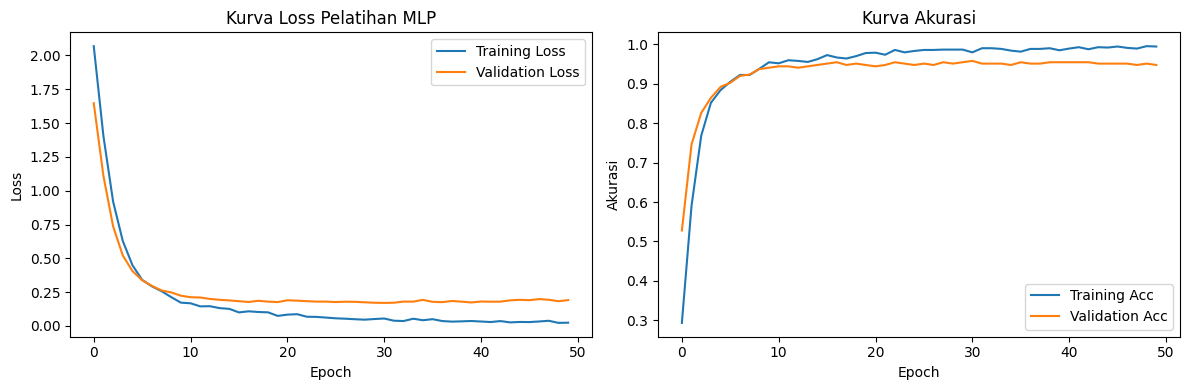

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="Training Loss")
ax[0].plot(history.history["val_loss"], label="Validation Loss")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Kurva Loss Pelatihan MLP"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="Training Acc")
ax[1].plot(history.history["val_accuracy"], label="Validation Acc")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Akurasi"); ax[1].set_title("Kurva Akurasi"); ax[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# Pembanding yang disarankan modul (12.13.1): Random Forest pada dataset yang sama
import time
from sklearn.ensemble import RandomForestClassifier
t0 = time.perf_counter()
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
t_rf = time.perf_counter() - t0
print(f"Random Forest: akurasi test = {rf.score(X_test, y_test):.3f}, waktu latih = {t_rf:.1f} s")
print(f"MLP          : akurasi test = {test_acc:.3f}")

Random Forest: akurasi test = 0.969, waktu latih = 2.3 s
MLP          : akurasi test = 0.983


### Praktikum 1 — Eksperimen Arsitektur MLP (Praktikum 12.7)

In [8]:
arsitektur_list = [[32], [64, 32], [128, 64, 32]]
hasil_arsitektur = []
for arsitektur in arsitektur_list:
    keras.utils.set_random_seed(42)
    layers = [keras.layers.Dense(n, activation="relu") for n in arsitektur]
    m = keras.Sequential([keras.layers.Input(shape=(X_train.shape[1],))] + layers +
                         [keras.layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(X_train, y_train, validation_split=0.2, epochs=30, verbose=0)
    print(f"Arsitektur {arsitektur}: val_accuracy akhir = {h.history['val_accuracy'][-1]:.3f}")
    hasil_arsitektur.append({"Arsitektur": str(arsitektur), "Parameter": m.count_params(),
                             "train_acc akhir": h.history["accuracy"][-1],
                             "val_acc akhir": h.history["val_accuracy"][-1],
                             "val_loss akhir": h.history["val_loss"][-1],
                             "val_loss minimum": min(h.history["val_loss"]),
                             "akurasi test": m.evaluate(X_test, y_test, verbose=0)[1]})
import pandas as pd
pd.DataFrame(hasil_arsitektur).set_index("Arsitektur").round(3)

Arsitektur [32]: val_accuracy akhir = 0.951
Arsitektur [64, 32]: val_accuracy akhir = 0.958
Arsitektur [128, 64, 32]: val_accuracy akhir = 0.965


,Parameter,train_acc akhir,val_acc akhir,val_loss akhir,val_loss minimum,akurasi test
Arsitektur,,,,,,
[32],2410,0.997,0.951,0.146,0.146,0.975
"[64, 32]",6570,1.000,0.958,0.138,0.136,0.969
"[128, 64, 32]",18986,1.000,0.965,0.151,0.148,0.983


### Praktikum 2 — Early Stopping (Praktikum 12.8)

In [9]:
def buat_model(dropout=0.3):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([
        keras.layers.Input(shape=(X_train.shape[1],)),
        keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(dropout),
        keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(dropout),
        keras.layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

# Tanpa early stopping: 100 epoch penuh
model_tanpa = buat_model()
h_tanpa = model_tanpa.fit(X_train, y_train, validation_split=0.2, epochs=100, verbose=0)

# Dengan early stopping
model_es = buat_model()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model_es.fit(X_train, y_train, validation_split=0.2, epochs=100, callbacks=[early_stop], verbose=0)
print("Pelatihan berhenti pada epoch:", len(history.history["loss"]))
print("Epoch terbaik (val_loss minimum):", int(np.argmin(history.history["val_loss"])) + 1)

for nama, m in [("Tanpa early stopping (100 epoch)", model_tanpa), ("Dengan early stopping", model_es)]:
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    print(f"{nama}: test loss={loss:.3f}, test acc={acc:.3f}")

Pelatihan berhenti pada epoch: 27
Epoch terbaik (val_loss minimum): 22
Tanpa early stopping (100 epoch): test loss=0.171, test acc=0.981
Dengan early stopping: test loss=0.100, test acc=0.975


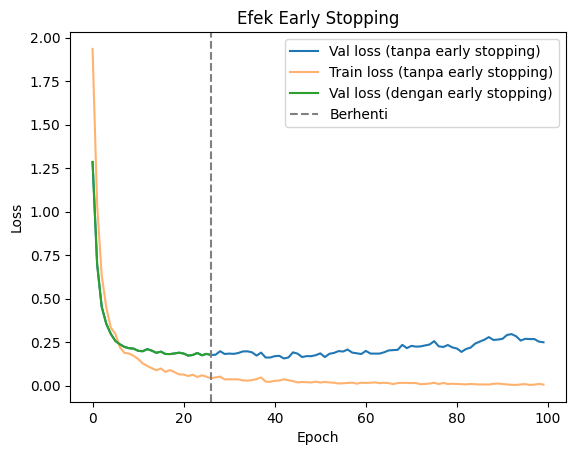

In [10]:
plt.plot(h_tanpa.history["val_loss"], label="Val loss (tanpa early stopping)")
plt.plot(h_tanpa.history["loss"], label="Train loss (tanpa early stopping)", alpha=.6)
plt.plot(history.history["val_loss"], label="Val loss (dengan early stopping)")
plt.axvline(len(history.history["loss"]) - 1, ls="--", color="gray", label="Berhenti")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Efek Early Stopping"); plt.show()